In [1]:
import matplotlib.pyplot as plt
from einops import rearrange
import numpy as np
import pickle
import torch
import math
import sys

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.fourier import isotropic_power_spectrum
from waveletflux.utils.well_data import get_well_dataset
from waveletflux.utils.plot import draw_movie, plot_psd
from waveletflux.utils.eval import build_stats_df

#well_dataset_name = 'turbulent_radiative_layer_2D'
#well_dataset_name = 'rayleigh_benard'
well_dataset_name = 'planetswe'

RESULT_DIR = f"{PROJECT_ROOT}/experiments/{well_dataset_name}/results"

In [3]:
well_base_path = f"{PROJECT_ROOT}/data/datasets"

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,
    transform = ['log_scalars'],   
    augment = [],
)

meta_fields = dataset.metadata.field_names
field_names = [item for sublist in meta_fields.values() for item in sublist]

In [2]:
model_paths = {
    #"WaveletFM-1scale"       : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_1scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales"      : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"LatentFM"               : f'{RESULT_DIR}/LatentFlow_turbulent_radiative_layer_2D_last_v1.0_fixed_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"LatentFM"               : f'{RESULT_DIR}/LatentFlow_{well_dataset_name}_last_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"LatentFM"               : f'{RESULT_DIR}/LatentFlow_{well_dataset_name}_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales"      : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales-last" : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales-last" : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_last_v3.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "UNetClassic"            : f'{RESULT_DIR}/UNetClassic_{well_dataset_name}_rollout_traj.pkl',
    "UNetConvNext"           : f'{RESULT_DIR}/UNetConvNext_{well_dataset_name}_rollout_traj.pkl',
    "FNO"                    : f'{RESULT_DIR}/FNO_{well_dataset_name}_rollout_traj.pkl',
    "TFNO"                   : f'{RESULT_DIR}/TFNO_{well_dataset_name}_rollout_traj.pkl',
}

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)
    print(f"Loaded rollout trajectory for {model}")

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)
    print("Loaded ground truth trajectory")


Loaded rollout trajectory for UNetClassic
Loaded rollout trajectory for UNetConvNext
Loaded rollout trajectory for FNO
Loaded rollout trajectory for TFNO
Loaded ground truth trajectory


# Benchmark Plot across Rollout Steps

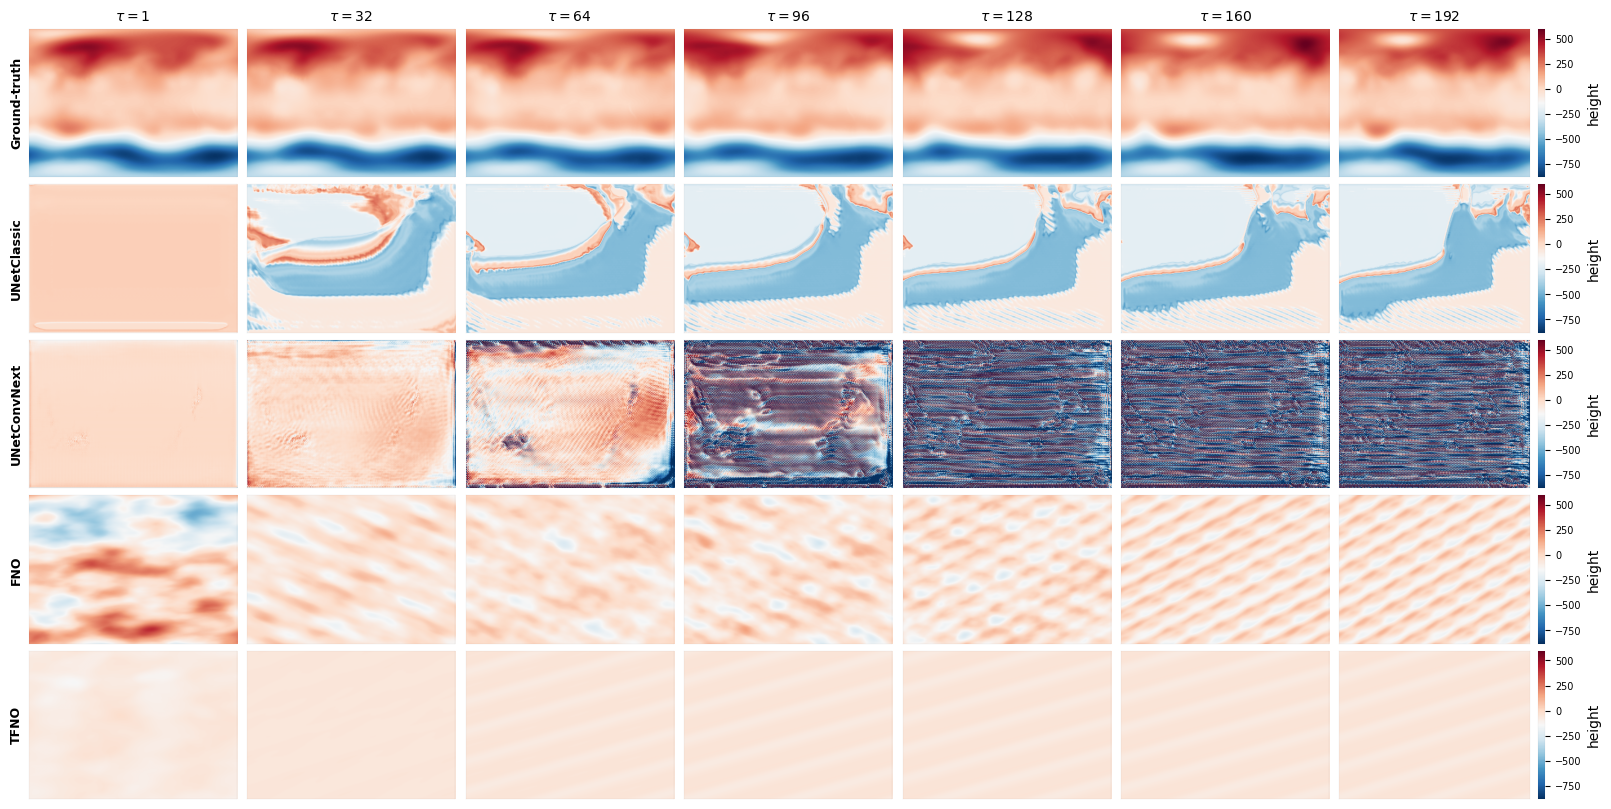

In [9]:
#models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales", "WaveletFM-3scales-last", "UNetClassic", "UNetConvNext"]
#models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales", "UNetClassic"]
#models_to_plot = ["WaveletFM-3scales", "UNetClassic", "UNetConvNext", "FNO"]
models_to_plot = ["UNetClassic", "UNetConvNext", "FNO", "TFNO"]
#models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales-last", "UNetClassic", "UNetConvNext"]
#models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales-last", "UNetClassic", "LatentFM"]

# ── Config ─────────────────────────────────────────────────────────────────────
TRAJ_IDX   = 5
ENS_IDX    = 0
Ti         = 4
field_idx  = 0
field_name = field_names[field_idx]
#lead_times = [1, 16, 32, 48, 64, 80, 96]
lead_times = [1, 32, 64, 96, 128, 160, 192]
#lead_times = [1, 2, 3, 4, 5, 6, 7]

# ── Frame helpers ──────────────────────────────────────────────────────────────
def get_gt_frame(tensor, traj_idx, lead, field):
    """
    tensor    : (N_TRAJ, rollout_steps, H, W, C)
    traj_idx  : trajectory index
    lead      : 1-indexed rollout step
             lead=1 → physical frame Ti+1, i.e. tensor[Ti + lead - 1]
    """
    return tensor[traj_idx, Ti + lead - 1, :, :, field]   

def get_pred_frame(tensor, traj_idx, ens_idx, lead, field):
    """
    tensor    : (N_TRAJ, N_ENSEMBLE, rollout_steps, H, W, C)
    traj_idx  : trajectory index
    ens_idx   : ensemble index
    lead      : 1-indexed rollout step → index = lead - 1
    """
    if len(tensor.shape) == 6:
        return tensor[traj_idx, ens_idx, lead - 1, :, :, field]
    return tensor[traj_idx, lead - 1, :, :, field]

# ── Results dict ───────────────────────────────────────────────────────────────

# ── Frames ─────────────────────────────────────────────────────────────────────
gt_frames = [get_gt_frame(truth_traj, TRAJ_IDX, t, field_idx) for t in lead_times]
model_frames = {
    name: [get_pred_frame(rollout_traj[name], TRAJ_IDX, ENS_IDX, t, field_idx) for t in lead_times]
    for name in models_to_plot
}

vmin = min(f.min() for f in gt_frames)
vmax = max(f.max() for f in gt_frames)

# ── Layout ─────────────────────────────────────────────────────────────────────
row_labels     = ["Ground-truth"] + models_to_plot
all_row_frames = [gt_frames] + [model_frames[name] for name in models_to_plot]
n_rows, n_cols = len(row_labels), len(lead_times)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(2.8 * n_cols, 2.0 * n_rows),
    gridspec_kw={"hspace": 0.05, "wspace": 0.05},
)
if n_rows == 1:
    axes = axes[None, :]

for ri, (frames, label) in enumerate(zip(all_row_frames, row_labels)):
    for ci, lead in enumerate(lead_times):
        ax = axes[ri, ci]
        im = ax.imshow(frames[ci], origin="lower", cmap="RdBu_r",
                       vmin=vmin, vmax=vmax, aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if ci == 0:
            ax.set_ylabel(label, fontsize=9, fontweight="bold")
        if ri == 0:
            ax.set_title(rf"$\tau={lead}$", fontsize=10, fontweight="bold")

    plt.rcParams["axes.linewidth"] = 0.02
    cbar = fig.colorbar(im, ax=axes[ri, -1], fraction=0.046, pad=0.04, label=field_name)
    cbar.ax.tick_params(labelsize=7)

plt.show()

# Draw Movie

In [ ]:
truth_traj.shape, rollout_traj['WaveletFM-1scale'].shape

## Baseline(s) vs GT

In [ ]:
TRAJ_IDX = 5

x_gt  = truth_traj[TRAJ_IDX, Ti:, ...]
#x_hat = rollout_traj['UNetClassic'][TRAJ_IDX, :-Ti, ...]
#x_hat = rollout_traj['UNetConvNext'][TRAJ_IDX, :-Ti, ...]
x_hat = rollout_traj['FNO'][TRAJ_IDX, :-Ti, ...]

frames = torch.stack((x_gt.mT, x_hat.mT))
frames = rearrange(frames, "N T H C W -> T N C H W")

draw_movie(frames, isolate={2}, fps=4.0, display=True, embed=True)

## WaveletFM vs GT

In [ ]:
TRAJ_IDX = 5

x_gt  = truth_traj[TRAJ_IDX, Ti:, ...]
#x_hat = rollout_traj['WaveletFM-1scale'][TRAJ_IDX, 0, :-Ti, ...]
#x_hat = rollout_traj['WaveletFM-3scales-last'][TRAJ_IDX, 0, :-Ti, ...]
x_hat = rollout_traj['WaveletFM-3scales'][TRAJ_IDX, 0, :-Ti, ...]

frames = torch.stack((x_gt.mT, x_hat.mT))
frames = rearrange(frames, "N T H C W -> T N C H W")

draw_movie(frames, isolate={2}, fps=4.0, display=True, embed=True)

# Plot PSD

In [ ]:
# ── Stack frames: (n_lead_times, H, W) ────────────────────────────────────────
# plot_psd expects (C, ...) — we use lead times as the "channel" dimension

gt_stacked = np.stack([np.asarray(f) for f in gt_frames], axis=0)
# shape: (n_lead_times, H, W)

psd_fields = [rf"$\tau={t}$" for t in lead_times]

# ── One PSD figure per model ───────────────────────────────────────────────────
for name in models_to_plot:
    model_stacked = np.stack([np.asarray(f) for f in model_frames[name]], axis=0)
    # shape: (n_lead_times, H, W)

    fig = plot_psd(
        x=gt_stacked,        # reference (GT), labeled "$x$" in the legend
        y=model_stacked,     # prediction, labeled "$y$" in the legend
        fields=psd_fields,   # subplot title per lead time
        figsize=(3.2, 3.2),
    )
    fig.suptitle(f"{field_name}  —  {name}", fontsize=11, fontweight="bold", y=1.01)
    fig.savefig(f"psd_{field_name}_{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

In [ ]:
lead_times

# Power Spectrum RMSE

In [ ]:
# Pick a single lead time to compare across all models
LEAD_IDX = 6   # e.g. lead_times[3] = 48

fig, axs = plt.subplots(1, 1, figsize=(5, 4))

gt_frame = np.asarray(gt_frames[LEAD_IDX])
p_gt, k = isotropic_power_spectrum(gt_frame[None], spatial=2)
axs.loglog(1 / k, p_gt.squeeze(), base=2, label="Ground-truth", color="black", linewidth=2)

colors = plt.cm.tab10.colors
for ci, name in enumerate(models_to_plot):
    frame = np.asarray(model_frames[name][LEAD_IDX])
    p_m, _ = isotropic_power_spectrum(frame[None], spatial=2)
    axs.loglog(1 / k, p_m.squeeze(), base=2, label=name, color=colors[ci], alpha=0.85)

axs.invert_xaxis()
axs.set_xticks([2**i for i in range(1, math.ceil(math.log2(1 / k[0].item())))])
axs.set_xlabel("wavelength ")
axs.set_ylabel("power spectrum density")
axs.set_title(rf"{field_name}  —  $\tau={lead_times[LEAD_IDX]}$", fontweight="bold")
axs.legend(fontsize=8)
fig.tight_layout()
plt.show()

# STATS

In [ ]:
# ── Assemble predictions dict ─────────────────────────────────────────────────
# Generative models: (N_TRAJ, N_ENS, STEPS, H, W, C)
# Baselines:         (N_TRAJ,        STEPS, H, W, C)  — automatically detected via ndim

predictions = {
    "WaveletFM-1scale":  rollout_traj["WaveletFM-1scale"][:, :, :-Ti, ...],   # (N_TRAJ, N_ENS, STEPS, H, W, C)
    "WaveletFM-3scales": rollout_traj["WaveletFM-3scales"][:, :, :-Ti, ...],  # (N_TRAJ, N_ENS, STEPS, H, W, C)
    "UNetClassic":       rollout_traj["UNetClassic"][:, :-Ti, ...],           # (N_TRAJ,        STEPS, H, W, C)
    "UNetConvNext":      rollout_traj["UNetConvNext"][:, :-Ti, ...],          # (N_TRAJ,        STEPS, H, W, C)
}

df = build_stats_df(
    truth        =  truth_traj[:, Ti:, ...],
    predictions  = predictions,
    field_names  = field_names,
    lead_times   = np.arange(97), # TODO : replace with actual lead times (lead_times)
    stride       = 1,
)


In [ ]:
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .mean()
    .round(4)
)
print(summary.to_string())

In [ ]:
df

In [ ]:
df[df["field"] == field_name]

In [ ]:
import seaborn as sb

aggregate=np.mean

table = df[df["field"] == field_name].copy()
palette = sb.cubehelix_palette(len(table["model"].unique()), dark=0.25)

sb.lineplot(table, x="time", y=f"vrmse",
            hue="model", estimator=aggregate, errorbar=None,
            palette=palette, ax=None)


plt.show()

In [ ]:
"""
# ── Per-field mosaic plots ────────────────────────────────────────────────────
for field in field_names:
    fig = plot_metrics(df, field_name=field, models_order=models_to_plot)
    fig.savefig(f"metrics_{field}.pdf", dpi=300, transparent=True, bbox_inches="tight")
    plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .median()
    .round(4)
)
print(summary.to_string())
"""

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from waveletflux.utils.fourier import isotropic_power_spectrum


def power_spectrum_rmse(
    u: torch.Tensor,           # ground-truth  (..., H, W)
    v: torch.Tensor,           # prediction    (..., H, W)
    n_bands: int = 3,
    spatial: int = 2,
    eps: float = 1e-8,
) -> tuple[torch.Tensor, list[str]]:
    """
    Computes the Power Spectrum RMSE (PS-RMSE) over log-spaced frequency bands.

    For each band, reports RMSE of the relative spectrum pv/pu around 1
    (perfect match = 0).

    Args:
        u        : Ground-truth field, shape (..., H, W)
        v        : Predicted field,    shape (..., H, W)
        n_bands  : Number of frequency bands (default 3: low / mid / high)
        spatial  : Number of spatial dimensions
        eps      : Stabiliser for division by near-zero GT power

    Returns:
        rmse_bands : Tensor of shape (..., n_bands)
        band_names : List of n_bands label strings
    """
    u = torch.as_tensor(u, dtype=torch.float32)
    v = torch.as_tensor(v, dtype=torch.float32)

    # p_*: (..., B),  freqs: (B,)  — linearly spaced in frequency space
    p_u, freqs = isotropic_power_spectrum(u, spatial=spatial)
    p_v, _     = isotropic_power_spectrum(v, spatial=spatial)

    # Relative power spectrum  (..., B)
    ratio = p_v / (p_u + eps)

    # ── Log-spaced band edges ──────────────────────────────────────────────────
    # freqs start slightly above 0; clamp to avoid log(0)
    log_f    = torch.log(freqs.clamp(min=1e-8))
    edges    = torch.linspace(log_f[0], log_f[-1], n_bands + 1)
    labels   = ["low", "mid", "high"][:n_bands]

    rmse_bands = []
    for i in range(n_bands):
        lo, hi = edges[i], edges[i + 1]
        # Include the rightmost bin in the last band
        mask = (log_f >= lo) & (log_f <= hi if i == n_bands - 1 else log_f < hi)
        ratio_band = ratio[..., mask]                             # (..., K)
        rmse = torch.sqrt(torch.mean((ratio_band - 1.0) ** 2, dim=-1))  # (...)
        rmse_bands.append(rmse)

    return torch.stack(rmse_bands, dim=-1), labels   # (..., n_bands)


# ── Evaluate across all lead times and models ─────────────────────────────────

def evaluate_ps_rmse(
    gt_frames:     list,         # len = n_lead_times, each (H, W)
    model_frames:  dict,         # model_name -> list of (H, W)
    lead_times:    list,
    field_name:    str = "field",
) -> pd.DataFrame:
    """
    Returns a DataFrame with columns:
        model | lead_time | band | ps_rmse
    """
    records = []

    for t_idx, lead in enumerate(lead_times):
        u = torch.as_tensor(np.asarray(gt_frames[t_idx]), dtype=torch.float32)

        for model_name, frames in model_frames.items():
            v = torch.as_tensor(np.asarray(frames[t_idx]), dtype=torch.float32)

            rmse, band_names = power_spectrum_rmse(u, v)

            for band, val in zip(band_names, rmse.tolist()):
                records.append({
                    "model":     model_name,
                    "lead_time": lead,
                    "band":      band,
                    "ps_rmse":   val,
                })

    return pd.DataFrame(records)


# ── Run ────────────────────────────────────────────────────────────────────────
df = evaluate_ps_rmse(gt_frames, model_frames, lead_times, field_name=field_name)

# ── Summary table (mean over lead times) ──────────────────────────────────────
summary = (
    df.groupby(["model", "band"])["ps_rmse"]
    .mean()
    .unstack("band")[["low", "mid", "high"]]   # enforce band order
    .round(4)
)
print(f"\nPS-RMSE ({field_name}) — mean over lead times\n")
print(summary.to_string())

# ── Plot: PS-RMSE vs lead time, one panel per band ────────────────────────────
band_names = ["low", "mid", "high"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=False)

colors = plt.cm.tab10.colors

for ax, band in zip(axes, band_names):
    sub = df[df["band"] == band]
    for ci, model in enumerate(models_to_plot):
        row = sub[sub["model"] == model]
        ax.plot(row["lead_time"], row["ps_rmse"],
                marker="o", markersize=4,
                label=model, color=colors[ci])
    ax.set_title(f"{band} freq.", fontweight="bold")
    ax.set_xlabel(r"lead time $\tau$")
    ax.set_ylabel("PS-RMSE" if band == "low" else "")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

fig.suptitle(f"Power Spectrum RMSE — {field_name}", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

In [ ]:



# ══════════════════════════════════════════════════════════════════════════════
# Plotting
# ══════════════════════════════════════════════════════════════════════════════

def plot_metrics(
    df:           pd.DataFrame,
    field_name:   str,
    models_order: list[str] | None = None,
    aggregate=np.median,
) -> plt.Figure:
    """
    Mosaic plot: VRMSE + Spread/Skill on the left, PS-RMSE bands on the right.
    Mirrors the reference plotting style.
    """
    table = df[df["field"] == field_name].copy()
    if models_order:
        table["model"] = pd.Categorical(table["model"], categories=models_order, ordered=True)

    palette = sb.cubehelix_palette(len(table["model"].unique()), dark=0.25)

    fig, axs = plt.subplot_mosaic(
        [[0, 2], [0, 2], [0, 3], [1, 3], [1, 4], [1, 4]],
        figsize=(6.4, 3.2),
        sharex=True,
        sharey=False,
    )

    # ── Left: VRMSE and Spread/Skill ──────────────────────────────────────────
    for i, (metric, ylabel) in enumerate([("vrmse", "VRMSE"), ("spread_skill", "Spread / Skill")]):
        ax = sb.lineplot(
            table, x="time", y=metric,
            hue="model", estimator=aggregate, errorbar=None,
            palette=palette, ax=axs[i],
        )
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.set_xlabel("Lead time")
        ax.set_ylabel(ylabel)
        ax.tick_params(direction="in")

    handles, labels = axs[0].get_legend_handles_labels()

    # ── Right: PS-RMSE per band ───────────────────────────────────────────────
    for i, band in enumerate(["low", "mid", "high"], start=2):
        ax = sb.lineplot(
            table, x="time", y=f"rmse_p_{band}",
            hue="model", estimator=aggregate, errorbar=None,
            palette=palette, ax=axs[i],
        )
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.set_xlabel("Lead time")
        ax.set_ylabel(band.capitalize())
        ax.tick_params(direction="in")
        ax.yaxis.set_label_position("right")
        ax.yaxis.label.set(rotation=-90, va="center")
        ax.yaxis.tick_right()
        if i == 2:
            ax.set_title("Power Spectrum RMSE")

    # ── Shared legend ─────────────────────────────────────────────────────────
    fig.align_labels()
    fig.tight_layout(pad=0.33)
    fig.subplots_adjust(top=0.875)
    fig.legend(handles, labels, loc="upper left", ncol=len(labels))
    fig.suptitle(field_name, x=0.5, y=0.98)

    return fig

In [ ]:
df

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from waveletflux.utils.plot import field2rgb

models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales", "UNetClassic", "UNetConvNext"]
field_names    = ['density', 'pressure', 'velocity_x', 'velocity_y']

TRAJ_IDX   = 8
ENS_IDX    = 0
Ti         = 4
field_idx  = 0
field_name = field_names[field_idx]
lead_times = [1, 16, 32, 48, 64, 80, 96]

def get_gt_frame(tensor, traj_idx, lead, field):
    return tensor[traj_idx, Ti + lead - 1, :, :, field]

def get_pred_frame(tensor, traj_idx, ens_idx, lead, field):
    if len(tensor.shape) == 6:
        return tensor[traj_idx, ens_idx, lead - 1, :, :, field]
    return tensor[traj_idx, lead - 1, :, :, field]

gt_frames = [get_gt_frame(truth_traj, TRAJ_IDX, t, field_idx) for t in lead_times]
model_frames = {
    name: [get_pred_frame(rollout_traj[name], TRAJ_IDX, ENS_IDX, t, field_idx) for t in lead_times]
    for name in models_to_plot
}

row_labels     = ["Ground-truth"] + models_to_plot
all_row_frames = [gt_frames] + [model_frames[name] for name in models_to_plot]
n_rows, n_cols = len(row_labels), len(lead_times)

# ── Compute shared vmin/vmax from ground-truth frames ─────────────────────────
vmin = float(min(f.min() for f in gt_frames))
vmax = float(max(f.max() for f in gt_frames))

# ── Convert all frames to RGB up-front ────────────────────────────────────────
# field2rgb expects any array shape; contrast=1.5 is the default
rgb_rows = [
    [field2rgb(frame, vmin=vmin, vmax=vmax, cmap="RdBu_r") for frame in row]
    for row in all_row_frames
]

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(2.8 * n_cols, 2.0 * n_rows),
    gridspec_kw={"hspace": 0.05, "wspace": 0.05},
)
if n_rows == 1:
    axes = axes[None, :]

plt.rcParams["axes.linewidth"] = 0.02

for ri, (rgb_frames, label) in enumerate(zip(rgb_rows, row_labels)):
    for ci, lead in enumerate(lead_times):
        ax = axes[ri, ci]
        # field2rgb already returns uint8 RGB — no cmap/vmin/vmax needed here
        ax.imshow(rgb_frames[ci], origin="lower", aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if ci == 0:
            ax.set_ylabel(label, fontsize=9, fontweight="bold")
        if ri == 0:
            ax.set_title(rf"$\tau={lead}$", fontsize=10, fontweight="bold")

    # Colorbar: build a ScalarMappable since we no longer have an imshow handle
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors
    sm = cm.ScalarMappable(norm=mcolors.Normalize(vmin=vmin, vmax=vmax), cmap="RdBu_r")
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes[ri, -1], fraction=0.046, pad=0.04, label=field_name)
    cbar.ax.tick_params(labelsize=7)

plt.show()